<a href="https://colab.research.google.com/github/danielbevilacqua2/Bootcamp-Ciberseguran-a-DIO/blob/main/laboratorio_defensivo_integridade_python.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Etapa 1 — Setup do Sandbox, Hashes Iniciais e Transformação/Restauração Reversível


In [1]:
from __future__ import annotations

import hashlib
import json
from pathlib import Path
from typing import Dict

from cryptography.fernet import Fernet, InvalidToken

# Diretório raiz isolado para a simulação educacional
SANDBOX_ROOT = Path("lab_sandbox").resolve()
TARGET_DIR = (SANDBOX_ROOT / "test_files").resolve()
ARTIFACTS_DIR = (SANDBOX_ROOT / "artifacts").resolve()
BASELINE_FILE = ARTIFACTS_DIR / "baseline_hashes.json"
KEY_FILE = ARTIFACTS_DIR / "lab_demo.key"


def _resolver_caminho_seguro(caminho: Path, base_permitida: Path = TARGET_DIR) -> Path:
    """Garante que o caminho alvo esteja estritamente dentro do diretório autorizado."""
    resolvido = caminho.resolve()
    if base_permitida not in resolvido.parents and resolvido != base_permitida:
        raise ValueError(f"Acesso bloqueado fora do diretório permitido: {resolvido}")
    return resolvido


def calcular_sha256(arquivo: Path) -> str:
    """Calcula o hash SHA-256 de um arquivo em blocos para evitar alto consumo de memória."""
    caminho_seguro = _resolver_caminho_seguro(arquivo)
    if not caminho_seguro.is_file():
        raise FileNotFoundError(f"Arquivo não encontrado: {caminho_seguro}")

    hasher = hashlib.sha256()
    with caminho_seguro.open("rb") as f:
        for bloco in iter(lambda: f.read(8192), b""):
            hasher.update(bloco)
    return hasher.hexdigest()


def preparar_ambiente_isolado() -> Dict[str, str]:
    """Cria a estrutura de pastas e arquivos fictícios de teste e registra o baseline SHA-256."""
    TARGET_DIR.mkdir(parents=True, exist_ok=True)
    ARTIFACTS_DIR.mkdir(parents=True, exist_ok=True)

    arquivos_ficticios: Dict[str, str] = {
        "credenciais_ficticias.txt": (
            "AMBIENTE_TESTE=LABORATORIO_EDUCACIONAL\n"
            "USUARIO_DEMO=aluno_teste\n"
            "TOKEN_FICTICIO=DEMO-TOKEN-0000-SAFE\n"
        ),
        "relatorio_financeiro_demo.txt": (
            "Relatório fictício de fluxo de caixa para análise de integridade.\n"
            "Receita simulada: R$ 10.000,00 | Despesa simulada: R$ 4.200,00\n"
        ),
        "notas_estudo.txt": (
            "Anotações de laboratório: verificar hashes SHA-256 antes e após "
            "a simulação reversível de transformação de arquivos.\n"
        ),
    }

    hashes_iniciais: Dict[str, str] = {}
    for nome_arquivo, conteudo in arquivos_ficticios.items():
        destino = _resolver_caminho_seguro(TARGET_DIR / nome_arquivo)
        destino.write_text(conteudo, encoding="utf-8")
        hashes_iniciais[nome_arquivo] = calcular_sha256(destino)

    BASELINE_FILE.write_text(
        json.dumps(hashes_iniciais, indent=2, ensure_ascii=False),
        encoding="utf-8",
    )
    print(f"[OK] Ambiente preparado em: {TARGET_DIR}")
    print(f"[OK] Baseline salvo em: {BASELINE_FILE} ({len(hashes_iniciais)} arquivos)")
    return hashes_iniciais


def obter_ou_criar_chave(chave_path: Path = KEY_FILE) -> bytes:
    """Carrega uma chave simétrica existente do laboratório ou gera uma nova em ARTIFACTS_DIR."""
    if chave_path.exists():
        return chave_path.read_bytes()
    chave = Fernet.generate_key()
    chave_path.write_bytes(chave)
    return chave


def listar_arquivos_alvo(diretorio: Path = TARGET_DIR) -> list[Path]:
    """Lista arquivos regulares dentro do diretório isolado de testes."""
    base = _resolver_caminho_seguro(diretorio)
    return [p for p in sorted(base.rglob("*")) if p.is_file()]


def transformar_arquivos_reversivel(chave: bytes, diretorio: Path = TARGET_DIR) -> int:
    """Aplica transformação reversível (Fernet) nos arquivos da pasta de testes."""
    fernet = Fernet(chave)
    arquivos = listar_arquivos_alvo(diretorio)
    processados = 0

    for arquivo in arquivos:
        caminho_seguro = _resolver_caminho_seguro(arquivo)
        try:
            dados_originais = caminho_seguro.read_bytes()
            dados_transformados = fernet.encrypt(dados_originais)
            caminho_seguro.write_bytes(dados_transformados)
            processados += 1
        except OSError as exc:
            print(f"[ERRO] Falha ao transformar '{caminho_seguro.name}': {exc}")

    print(f"[OK] Transformação reversível concluída em {processados} arquivo(s).")
    return processados


def restaurar_arquivos_reversivel(chave: bytes, diretorio: Path = TARGET_DIR) -> int:
    """Reverte a transformação Fernet e restaura o conteúdo original dos arquivos."""
    fernet = Fernet(chave)
    arquivos = listar_arquivos_alvo(diretorio)
    restaurados = 0

    for arquivo in arquivos:
        caminho_seguro = _resolver_caminho_seguro(arquivo)
        try:
            dados_cifrados = caminho_seguro.read_bytes()
            dados_restaurados = fernet.decrypt(dados_cifrados)
            caminho_seguro.write_bytes(dados_restaurados)
            restaurados += 1
        except InvalidToken:
            print(f"[AVISO] Chave inválida ou arquivo não transformado: '{caminho_seguro.name}'")
        except OSError as exc:
            print(f"[ERRO] Falha ao restaurar '{caminho_seguro.name}': {exc}")

    print(f"[OK] Restauração concluída em {restaurados} arquivo(s).")
    return restaurados


if __name__ == "__main__":
    try:
        baseline = preparar_ambiente_isolado()
        chave_lab = obter_ou_criar_chave()

        print("\n--- Simulando transformação reversível ---")
        transformar_arquivos_reversivel(chave_lab)

        print("\n--- Simulando restauração dos arquivos ---")
        restaurar_arquivos_reversivel(chave_lab)

        hashes_finais = {
            arq.name: calcular_sha256(arq) for arq in listar_arquivos_alvo(TARGET_DIR)
        }
        integridade_ok = hashes_finais == baseline
        print(f"\n[RESULTADO] Integridade restaurada idêntica ao baseline? {integridade_ok}")
    except Exception as erro:
        print(f"[FALHA CRÍTICA] {erro}")

[OK] Ambiente preparado em: /content/lab_sandbox/test_files
[OK] Baseline salvo em: /content/lab_sandbox/artifacts/baseline_hashes.json (3 arquivos)

--- Simulando transformação reversível ---
[OK] Transformação reversível concluída em 3 arquivo(s).

--- Simulando restauração dos arquivos ---
[OK] Restauração concluída em 3 arquivo(s).

[RESULTADO] Integridade restaurada idêntica ao baseline? True


In [4]:
from pathlib import Path
import pandas as pd

# Certifique-se de que as funções da Etapa 1 e Etapa 2 já foram executadas no notebook
SANDBOX_ROOT = Path("lab_sandbox").resolve()
TARGET_DIR = (SANDBOX_ROOT / "test_files").resolve()
ARTIFACTS_DIR = (SANDBOX_ROOT / "artifacts").resolve()

print("=== 1. PREPARANDO BASELINE E APLICANDO TRANSFORMAÇÃO (SEM RESTAURAR AINDA) ===")
preparar_ambiente_isolado()
chave_lab = obter_ou_criar_chave()
transformar_arquivos_reversivel(chave_lab)

print("\n=== 2. VERIFICAÇÃO INTERMEDIÁRIA (ESPERADO: STATUS ALTERADO) ===")
df_alterado = verificar_integridade_e_gerar_relatorio(exportar_csv=False)
df_alterado.to_csv(ARTIFACTS_DIR / "relatorio_alteracao_detectada.csv", index=False, encoding="utf-8")
print(df_alterado.to_string(index=False))

print("\n=== 3. RESTAURANDO ARQUIVOS E VALIDANDO RECUPERAÇÃO (ESPERADO: INTEGRO) ===")
restaurar_arquivos_reversivel(chave_lab)
df_pos_restauracao = verificar_integridade_e_gerar_relatorio(exportar_csv=True)
print(df_pos_restauracao.to_string(index=False))

=== 1. PREPARANDO BASELINE E APLICANDO TRANSFORMAÇÃO (SEM RESTAURAR AINDA) ===
[OK] Ambiente preparado em: /content/lab_sandbox/test_files
[OK] Baseline salvo em: /content/lab_sandbox/artifacts/baseline_hashes.json (3 arquivos)
[OK] Transformação reversível concluída em 3 arquivo(s).

=== 2. VERIFICAÇÃO INTERMEDIÁRIA (ESPERADO: STATUS ALTERADO) ===
                      arquivo status_integridade  tamanho_bytes   hash_sha256_atual                   alerta_defensivo
    credenciais_ficticias.txt           ALTERADO            228 35cc21a939237b93... ALTA - Divergência de hash SHA-256
             notas_estudo.txt           ALTERADO            248 f1a68b906ba99c87... ALTA - Divergência de hash SHA-256
relatorio_financeiro_demo.txt           ALTERADO            268 b581a817fea5df4c... ALTA - Divergência de hash SHA-256

=== 3. RESTAURANDO ARQUIVOS E VALIDANDO RECUPERAÇÃO (ESPERADO: INTEGRO) ===
[OK] Restauração concluída em 3 arquivo(s).
[OK] Relatório tabular salvo em: /content/lab_sandbo

Etapa 2 — Registro Simulado de Eventos, Comparação de Integridade e Relatório com pandas


In [2]:
from __future__ import annotations

from datetime import datetime, timezone
import json
from pathlib import Path
from typing import Dict, List

import pandas as pd

# Reutiliza a estrutura de diretórios da Etapa 1
SANDBOX_ROOT = Path("lab_sandbox").resolve()
TARGET_DIR = (SANDBOX_ROOT / "test_files").resolve()
ARTIFACTS_DIR = (SANDBOX_ROOT / "artifacts").resolve()
BASELINE_FILE = ARTIFACTS_DIR / "baseline_hashes.json"
EVENT_LOG_FILE = ARTIFACTS_DIR / "eventos_simulados.log"
REPORT_CSV_FILE = ARTIFACTS_DIR / "relatorio_integridade.csv"

# Teclas de controle ignoradas na formatação didática (espelhando a lógica do curso)
TECLAS_IGNORADAS = {
    "Key.shift",
    "Key.shift_l",
    "Key.shift_r",
    "Key.ctrl",
    "Key.ctrl_l",
    "Key.ctrl_r",
    "Key.alt",
    "Key.alt_l",
    "Key.alt_r",
    "Key.caps_lock",
    "Key.cmd",
}


def _resolver_caminho_seguro(caminho: Path, base_permitida: Path = SANDBOX_ROOT) -> Path:
    """Garante que o caminho permaneça estritamente dentro de SANDBOX_ROOT."""
    resolvido = caminho.resolve()
    if base_permitida not in resolvido.parents and resolvido != base_permitida:
        raise ValueError(f"Acesso bloqueado fora do sandbox: {resolvido}")
    return resolvido


def formatar_evento_tecla(token_evento: str) -> str:
    """Converte tokens simulados de tecla em representação legível de auditoria."""
    if token_evento in TECLAS_IGNORADAS:
        return ""
    if token_evento == "Key.space":
        return " "
    if token_evento == "Key.enter":
        return "\n"
    if token_evento == "Key.tab":
        return "\t"
    if len(token_evento) == 1:
        return token_evento
    return f"[{token_evento}]"


def simular_registro_eventos_entrada(
    sequencia_eventos: List[str] | None = None,
    arquivo_saida: Path = EVENT_LOG_FILE,
) -> Path:
    """Registra uma sequência simulada de eventos de entrada em arquivo UTF-8 isolado."""
    ARTIFACTS_DIR.mkdir(parents=True, exist_ok=True)
    destino = _resolver_caminho_seguro(arquivo_saida, ARTIFACTS_DIR)

    if sequencia_eventos is None:
        sequencia_eventos = [
            "Key.shift_l",
            "t",
            "e",
            "s",
            "t",
            "e",
            "Key.space",
            "d",
            "e",
            "Key.space",
            "l",
            "o",
            "g",
            "Key.enter",
            "a",
            "u",
            "d",
            "i",
            "t",
            "o",
            "r",
            "i",
            "a",
            "Key.tab",
            "2026",
            "Key.enter",
        ]

    buffer_formatado = "".join(formatar_evento_tecla(tok) for tok in sequencia_eventos)
    timestamp = datetime.now(timezone.utc).isoformat()

    conteudo_log = (
        f"=== SIMULACAO DE EVENTOS DE ENTRADA (AMBIENTE ISOLADO) ===\n"
        f"Timestamp UTC: {timestamp}\n"
        f"Total de eventos processados: {len(sequencia_eventos)}\n"
        f"--- Conteudo Reconstruido ---\n"
        f"{buffer_formatado}\n"
        f"===========================================================\n"
    )
    destino.write_text(conteudo_log, encoding="utf-8")
    print(f"[OK] Log simulado de eventos salvo em: {destino}")
    return destino


def carregar_baseline(baseline_path: Path = BASELINE_FILE) -> Dict[str, str]:
    """Carrega o dicionário de hashes SHA-256 iniciais do arquivo baseline."""
    caminho_seguro = _resolver_caminho_seguro(baseline_path, ARTIFACTS_DIR)
    if not caminho_seguro.exists():
        raise FileNotFoundError(
            f"Baseline não encontrado em '{caminho_seguro}'. Execute a Etapa 1 primeiro."
        )
    dados = json.loads(caminho_seguro.read_text(encoding="utf-8"))
    return {str(k): str(v) for k, v in dados.items()}


def _hash_arquivo_alvo(arquivo: Path) -> str:
    """Calcula SHA-256 de um arquivo dentro de TARGET_DIR."""
    import hashlib

    caminho_seguro = _resolver_caminho_seguro(arquivo, TARGET_DIR)
    hasher = hashlib.sha256()
    with caminho_seguro.open("rb") as f:
        for bloco in iter(lambda: f.read(8192), b""):
            hasher.update(bloco)
    return hasher.hexdigest()


def verificar_integridade_e_gerar_relatorio(
    baseline_path: Path = BASELINE_FILE,
    target_dir: Path = TARGET_DIR,
    exportar_csv: bool = True,
) -> pd.DataFrame:
    """Compara o estado atual de TARGET_DIR com o baseline e retorna DataFrame do pandas."""
    baseline = carregar_baseline(baseline_path)
    base_alvo = _resolver_caminho_seguro(target_dir, SANDBOX_ROOT)
    base_alvo.mkdir(parents=True, exist_ok=True)

    arquivos_atuais = {
        p.name: p for p in sorted(base_alvo.iterdir()) if p.is_file()
    }
    todos_nomes = sorted(set(baseline.keys()) | set(arquivos_atuais.keys()))

    registros: List[Dict[str, object]] = []
    for nome in todos_nomes:
        hash_esperado = baseline.get(nome)
        caminho_atual = arquivos_atuais.get(nome)

        if caminho_atual is None:
            status = "AUSENTE"
            hash_atual = "-"
            tamanho_bytes = 0
            alerta = "ALTA - Arquivo do baseline não encontrado"
        else:
            hash_atual = _hash_arquivo_alvo(caminho_atual)
            tamanho_bytes = caminho_atual.stat().st_size
            if hash_esperado is None:
                status = "NOVO_ARQUIVO"
                alerta = "MEDIA - Arquivo inesperado no diretório alvo"
            elif hash_atual == hash_esperado:
                status = "INTEGRO"
                alerta = "NENHUM"
            else:
                status = "ALTERADO"
                alerta = "ALTA - Divergência de hash SHA-256"

        registros.append(
            {
                "arquivo": nome,
                "status_integridade": status,
                "tamanho_bytes": tamanho_bytes,
                "hash_sha256_atual": hash_atual[:16] + ("..." if len(hash_atual) > 16 else ""),
                "alerta_defensivo": alerta,
            }
        )

    df = pd.DataFrame(registros)

    if exportar_csv:
        ARTIFACTS_DIR.mkdir(parents=True, exist_ok=True)
        df.to_csv(REPORT_CSV_FILE, index=False, encoding="utf-8")
        print(f"[OK] Relatório tabular salvo em: {REPORT_CSV_FILE}")

    return df


if __name__ == "__main__":
    try:
        simular_registro_eventos_entrada()
        relatorio_df = verificar_integridade_e_gerar_relatorio()
        print("\n=== RELATORIO CONSOLIDADO DE INTEGRIDADE (PANDAS) ===")
        print(relatorio_df.to_string(index=False))
    except Exception as erro:
        print(f"[FALHA NA ETAPA 2] {erro}")

[OK] Log simulado de eventos salvo em: /content/lab_sandbox/artifacts/eventos_simulados.log
[OK] Relatório tabular salvo em: /content/lab_sandbox/artifacts/relatorio_integridade.csv

=== RELATORIO CONSOLIDADO DE INTEGRIDADE (PANDAS) ===
                      arquivo status_integridade  tamanho_bytes   hash_sha256_atual alerta_defensivo
    credenciais_ficticias.txt            INTEGRO            100 2cfa79a5e703cb41...           NENHUM
             notas_estudo.txt            INTEGRO            126 4ba7c0da32c58f96...           NENHUM
relatorio_financeiro_demo.txt            INTEGRO            132 bdf3457fc26f1e7c...           NENHUM


Etapa 3 — Gráfico com matplotlib e Geração Automática de README.md


In [3]:
from __future__ import annotations

from datetime import datetime, timezone
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

# Reutiliza a estrutura de diretórios das Etapas 1 e 2
SANDBOX_ROOT = Path("lab_sandbox").resolve()
ARTIFACTS_DIR = (SANDBOX_ROOT / "artifacts").resolve()
REPORT_CSV_FILE = ARTIFACTS_DIR / "relatorio_integridade.csv"
CHART_PNG_FILE = ARTIFACTS_DIR / "resumo_integridade.png"
README_OUT_FILE = SANDBOX_ROOT / "README_GERADO.md"


def _resolver_caminho_seguro(caminho: Path, base_permitida: Path = SANDBOX_ROOT) -> Path:
    """Garante que qualquer leitura ou escrita fique restrita ao diretório SANDBOX_ROOT."""
    resolvido = caminho.resolve()
    if base_permitida not in resolvido.parents and resolvido != base_permitida:
        raise ValueError(f"Acesso bloqueado fora do sandbox: {resolvido}")
    return resolvido


def carregar_relatorio_pandas(csv_path: Path = REPORT_CSV_FILE) -> pd.DataFrame:
    """Carrega o relatório de integridade gerado pela Etapa 2 em um DataFrame do pandas."""
    caminho_seguro = _resolver_caminho_seguro(csv_path, ARTIFACTS_DIR)
    if not caminho_seguro.exists():
        raise FileNotFoundError(
            f"Relatório CSV não encontrado em '{caminho_seguro}'. Execute a Etapa 2 primeiro."
        )
    df = pd.read_csv(caminho_seguro, encoding="utf-8")
    if df.empty:
        raise ValueError("O relatório de integridade está vazio.")
    return df


def gerar_grafico_integridade(
    df: pd.DataFrame,
    saida_png: Path = CHART_PNG_FILE,
) -> Path:
    """Gera um gráfico de duas colunas com matplotlib sobre integridade e tamanho de arquivos."""
    ARTIFACTS_DIR.mkdir(parents=True, exist_ok=True)
    destino = _resolver_caminho_seguro(saida_png, ARTIFACTS_DIR)

    contagem_status = df["status_integridade"].value_counts()

    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.5))
    fig.suptitle(
        "Análise Defensiva — Integridade e Tamanho dos Arquivos em Sandbox",
        fontsize=12,
        fontweight="bold",
    )

    # Painel 1: Quantidade de arquivos por status de integridade
    ax1.bar(
        contagem_status.index.astype(str),
        contagem_status.values,
        color="#2b6cb0",
    )
    ax1.set_title("Arquivos por Status de Integridade")
    ax1.set_xlabel("Status")
    ax1.set_ylabel("Quantidade")
    ax1.tick_params(axis="x", rotation=20)
    ax1.grid(axis="y", linestyle="--", alpha=0.4)

    # Painel 2: Tamanho dos arquivos em bytes
    ax2.barh(
        df["arquivo"].astype(str),
        df["tamanho_bytes"].astype(float),
        color="#2f855a",
    )
    ax2.set_title("Tamanho Atual por Arquivo (Bytes)")
    ax2.set_xlabel("Tamanho (bytes)")
    ax2.set_ylabel("Arquivo")
    ax2.grid(axis="x", linestyle="--", alpha=0.4)

    plt.tight_layout(rect=[0, 0.03, 1, 0.93])
    plt.savefig(destino, dpi=150)
    plt.close(fig)

    print(f"[OK] Gráfico salvo em: {destino}")
    return destino


def gerar_readme_defensivo(
    df: pd.DataFrame,
    saida_md: Path = README_OUT_FILE,
) -> Path:
    """Gera um rascunho estruturado de README.md com resultados e medidas preventivas."""
    SANDBOX_ROOT.mkdir(parents=True, exist_ok=True)
    destino = _resolver_caminho_seguro(saida_md, SANDBOX_ROOT)
    timestamp_utc = datetime.now(timezone.utc).strftime("%Y-%m-%d %H:%M UTC")

    tabela_markdown = df.to_markdown(index=False)

    conteudo_readme = f"""# Laboratório Educacional de Análise Defensiva e Integridade em Python

> **Aviso Educacional:** Projeto desenvolvido exclusivamente para fins didáticos e de defesa cibernética em ambiente isolado (`lab_sandbox/`). Nenhuma rotina ofensiva real, captura de teclado externa ou exfiltração remota é executada.

Gerado automaticamente em: `{timestamp_utc}`

## 1. Objetivo do Laboratório
Consolidar a compreensão prática sobre:
- Monitoramento de integridade de arquivos (FIM) por meio de hashes **SHA-256**.
- Transformação e restauração reversível de arquivos em ambiente controlado para estudo de impacto e recuperação.
- Registro estruturado de eventos simulados e análise tabular/visual com `pandas` e `matplotlib`.

## 2. Resumo da Verificação de Integridade
{tabela_markdown}

## 3. Estratégias de Prevenção e Defesa
- **Autenticação Multifator (MFA):** reduz o risco de uso indevido de credenciais caso haja comprometimento de conta ou exposição de dados.
- **Sandboxing e Isolamento:** restringe a execução de scripts e experimentos a diretórios e ambientes controlados, evitando impacto em sistemas críticos.
- **Antivírus e EDR:** monitoram comportamentos anômalos, alterações em lote de arquivos e execução de processos não homologados.
- **Firewall e Controle de Rede:** limitam conexões de saída não autorizadas e reduzem superfícies de exposição.
- **Conscientização do Usuário:** treina equipes para reconhecer engenharia social, phishing e anexos suspeitos antes de abrir ou executar qualquer arquivo.

## 4. Como Executar
Execute os scripts das Etapas 1, 2 e 3 em sequência dentro de um ambiente Python 3 (como o Google Colab ou VS Code) com `cryptography`, `pandas` e `matplotlib` instalados.
"""
    destino.write_text(conteudo_readme, encoding="utf-8")
    print(f"[OK] Rascunho de README.md salvo em: {destino}")
    return destino


if __name__ == "__main__":
    try:
        relatorio_df = carregar_relatorio_pandas()
        gerar_grafico_integridade(relatorio_df)
        gerar_readme_defensivo(relatorio_df)
        print("\n[CONCLUIDO] Todas as etapas do laboratório defensivo foram finalizadas.")
    except Exception as erro:
        print(f"[FALHA NA ETAPA 3] {erro}")

[OK] Gráfico salvo em: /content/lab_sandbox/artifacts/resumo_integridade.png
[OK] Rascunho de README.md salvo em: /content/lab_sandbox/README_GERADO.md

[CONCLUIDO] Todas as etapas do laboratório defensivo foram finalizadas.


Gráfico gerado na análise defensiva


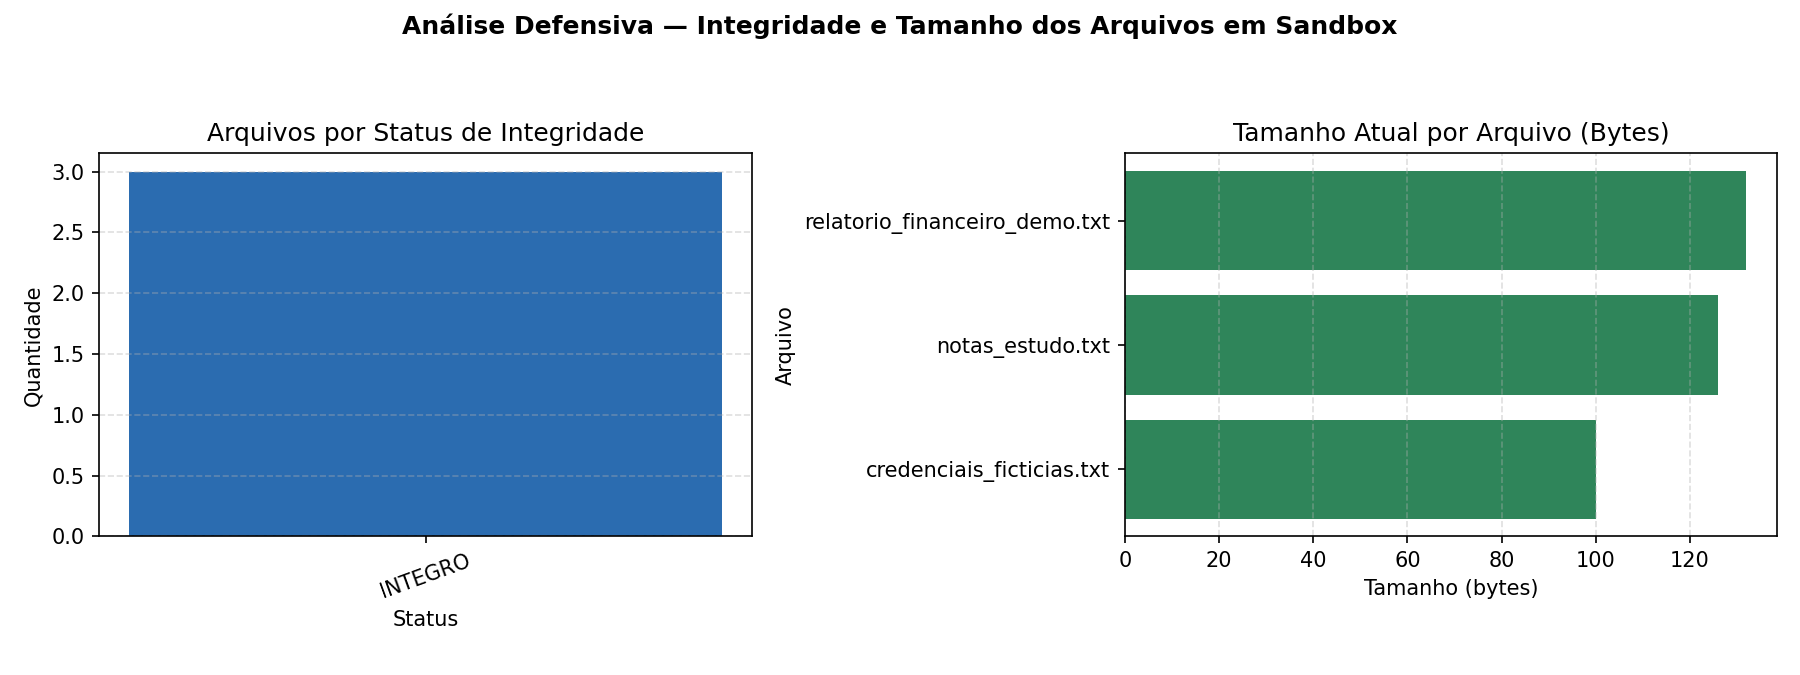

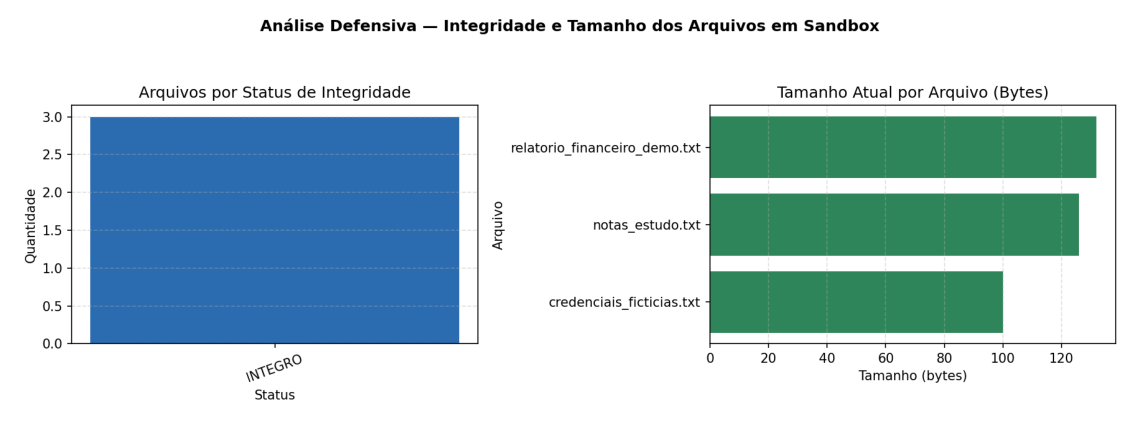

In [5]:
from pathlib import Path
from IPython.display import Image, display
import matplotlib.pyplot as plt
import matplotlib.image as mpimg

grafico_path = Path("/content/lab_sandbox/artifacts/resumo_integridade.png")

if not grafico_path.exists():
    # Fallback relativo caso esteja rodando fora de /content
    grafico_path = Path("lab_sandbox/artifacts/resumo_integridade.png")

if grafico_path.exists():
    # Opção 1: Exibir imagem diretamente via IPython.display
    display(Image(filename=str(grafico_path)))

    # Opção 2: Exibir via matplotlib sem eixos extras
    img = mpimg.imread(str(grafico_path))
    plt.figure(figsize=(12, 4.5))
    plt.imshow(img)
    plt.axis("off")
    plt.tight_layout()
    plt.show()
else:
    print(f"[AVISO] Arquivo não encontrado em '{grafico_path}'. Execute a Etapa 3 primeiro.")